In [1]:
pip install opencv-python numpy matplotlib

Note: you may need to restart the kernel to use updated packages.


Write a program to sharpen the input image using:
1. Laplacian filter
2. Gradient operators of Sobel and Canny edge detector
3. Unsharp masking. To obtain blurred image, use the Gaussian filter of size 5x5
and sigma= 3

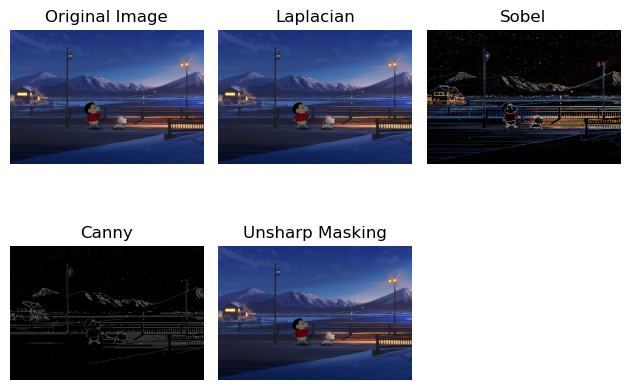

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Read input image
img = cv2.imread('wallpaper.jpg')
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

# 1. Laplacian Filter
lap = cv2.Laplacian(img, cv2.CV_64F)
lap = np.uint8(np.clip(img - lap, 0, 255))

# 2. Sobel Operator
sobelx = cv2.Sobel(img, cv2.CV_64F, 1, 0, ksize=3)
sobely = cv2.Sobel(img, cv2.CV_64F, 0, 1, ksize=3)
sobel = cv2.magnitude(sobelx, sobely)
sobel = np.uint8(np.clip(sobel, 0, 255))

# Canny Edge Detector
gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
canny = cv2.Canny(gray, 100, 200)

# 3. Unsharp Masking
blur = cv2.GaussianBlur(img, (5, 5), 3)
unsharp = cv2.addWeighted(img, 1.5, blur, -0.5, 0)

# Display results
titles = ['Original Image', 'Laplacian', 'Sobel',
          'Canny', 'Unsharp Masking']

images = [img, lap, sobel, canny, unsharp]

for i in range(5):
    plt.subplot(2, 3, i+1)
    plt.imshow(images[i], cmap='gray')
    plt.title(titles[i])
    plt.axis('off')

plt.tight_layout()
plt.show()